In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df = pd.read_csv('../part3_synthetic_data/data/sales.csv')
df['date'] = pd.to_datetime(df['date'])
df['revenue'] = df['qty'] * df['price']

weekly_sales = df.groupby(['category', pd.Grouper(key='date', freq='W-MON')])['revenue'].sum().reset_index()
weekly_sales = weekly_sales.sort_values(['category', 'date'])

display(weekly_sales.head())
print(weekly_sales['category'].unique())

,category,date,revenue
0,Выпечка,2022-01-03,208452.39
1,Выпечка,2022-01-10,425461.87
2,Выпечка,2022-01-17,417433.94
3,Выпечка,2022-01-24,481546.95
4,Выпечка,2022-01-31,404502.65


<StringArray>
['Выпечка', 'Молочные', 'Напитки']
Length: 3, dtype: str


MAE (Сезонный наивный): 96758.08
MAE (Скользящее среднее): 62213.79


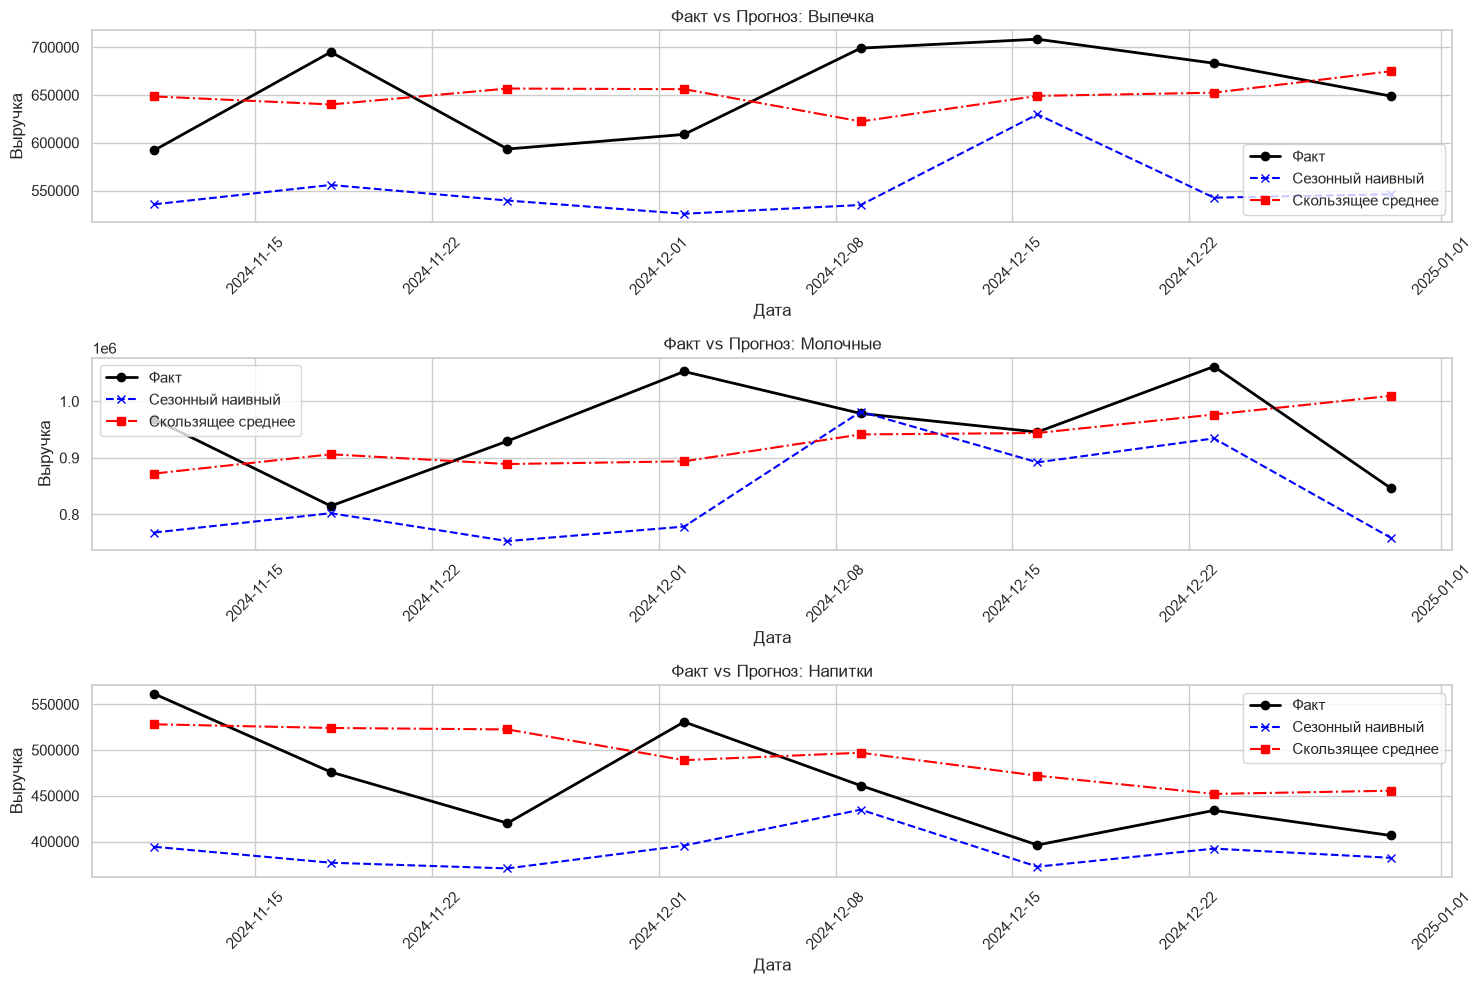

In [2]:
df_sorted = weekly_sales.sort_values(['category', 'date']).copy()

df_sorted['pred_naive'] = df_sorted.groupby('category')['revenue'].shift(52)
df_sorted['pred_ma'] = df_sorted.groupby('category')['revenue'].transform(lambda x: x.rolling(4).mean().shift(1))

test_size = 8
test = df_sorted.groupby('category').tail(test_size).copy()
train = df_sorted.drop(test.index).copy()

mae_naive = np.mean(np.abs(test['revenue'] - test['pred_naive']))
mae_ma = np.mean(np.abs(test['revenue'] - test['pred_ma']))

print(f"MAE (Сезонный наивный): {mae_naive:.2f}")
print(f"MAE (Скользящее среднее): {mae_ma:.2f}")

categories = test['category'].unique()

plt.figure(figsize=(15, 10))
for i, cat in enumerate(categories, 1):
    plt.subplot(3, 1, i)
    cat_data = test[test['category'] == cat]
    
    plt.plot(cat_data['date'], cat_data['revenue'], marker='o', label='Факт', color='black', linewidth=2)
    plt.plot(cat_data['date'], cat_data['pred_naive'], marker='x', linestyle='--', label='Сезонный наивный', color='blue')
    plt.plot(cat_data['date'], cat_data['pred_ma'], marker='s', linestyle='-.', label='Скользящее среднее', color='red')
    
    plt.title(f'Факт vs Прогноз: {cat}')
    plt.xlabel('Дата')
    plt.ylabel('Выручка')
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)

plt.tight_layout()
plt.show()